In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import pandas as pd, ast, os

BASE = '/content/drive/MyDrive/ECG_Project/PTB-XL/ptb-xl-a-large-publicly-available-electrocardiography-dataset-1.0.3'

df = pd.read_csv(os.path.join(BASE, 'ptbxl_database.csv'), index_col='ecg_id')
df['scp_codes'] = df['scp_codes'].apply(ast.literal_eval)   # string -> dict

scp = pd.read_csv(os.path.join(BASE, 'scp_statements.csv'), index_col=0)

print("Records:", len(df))
print("Unique patients:", df['patient_id'].nunique())
print("\nFold distribution:")
print(df['strat_fold'].value_counts().sort_index())
print("\nExample scp_codes:")
print(df['scp_codes'].head(3))
print("\nOfficial descriptions of our target codes:")
print(scp.loc[['1AVB','CRBBB','IRBBB','CLBBB','ILBBB','SBRAD','AFIB','STACH'],
              ['description','diagnostic','rhythm','form']])

Mounted at /content/drive
Records: 21799
Unique patients: 18869

Fold distribution:
strat_fold
1     2175
2     2181
3     2192
4     2174
5     2174
6     2173
7     2176
8     2173
9     2183
10    2198
Name: count, dtype: int64

Example scp_codes:
ecg_id
1    {'NORM': 100.0, 'LVOLT': 0.0, 'SR': 0.0}
2                {'NORM': 80.0, 'SBRAD': 0.0}
3                  {'NORM': 100.0, 'SR': 0.0}
Name: scp_codes, dtype: object

Official descriptions of our target codes:
                                description  diagnostic  rhythm  form
1AVB                  first degree AV block         1.0     NaN   NaN
CRBBB    complete right bundle branch block         1.0     NaN   NaN
IRBBB  incomplete right bundle branch block         1.0     NaN   NaN
CLBBB     complete left bundle branch block         1.0     NaN   NaN
ILBBB   incomplete left bundle branch block         1.0     NaN   NaN
SBRAD                     sinus bradycardia         NaN     1.0   NaN
AFIB                    atrial fibrilla

In [ ]:
# Mapping: model output -> list of PTB-XL SCP codes (merged where needed)
MAPPING = {
    '1dAVb': ['1AVB'],
    'RBBB' : ['CRBBB', 'IRBBB'],
    'LBBB' : ['CLBBB', 'ILBBB'],
    'SB'   : ['SBRAD'],
    'AF'   : ['AFIB'],
    'ST'   : ['STACH'],
}

# A) Count each raw code two ways: key present vs. value > 0
print("Raw SCP code counts (all 21,799 records):")
print(f"{'code':8s} {'key present':>12s} {'value > 0':>10s}")
for code in ['1AVB','CRBBB','IRBBB','CLBBB','ILBBB','SBRAD','AFIB','STACH']:
    present = df['scp_codes'].apply(lambda d: code in d).sum()
    positive = df['scp_codes'].apply(lambda d: d.get(code, 0) > 0).sum()
    print(f"{code:8s} {present:12d} {positive:10d}")

# B) Build the six merged labels using key presence
labels = pd.DataFrame(index=df.index)
for name, codes in MAPPING.items():
    labels[name] = df['scp_codes'].apply(lambda d: int(any(c in d for c in codes)))

LABELS = list(MAPPING.keys())
print("\nMerged label counts (overall):")
print(labels[LABELS].sum())

# C) Counts per split group
split = df['strat_fold'].map(lambda f: 'train(1-8)' if f <= 8 else ('val(9)' if f == 9 else 'test(10)'))
print("\nPositives per split:")
print(labels[LABELS].groupby(split).sum())
print("\nRecords per split:")
print(split.value_counts())

# D) Multi-label check
n_pos = labels[LABELS].sum(axis=1)
print("\nRecords with 0 target labels:", (n_pos == 0).sum())
print("Records with 1 target label :", (n_pos == 1).sum())
print("Records with 2+ target labels:", (n_pos >= 2).sum())

Raw SCP code counts (all 21,799 records):
code      key present  value > 0
1AVB              793        793
CRBBB             541        541
IRBBB            1118       1118
CLBBB             536        536
ILBBB              77         77
SBRAD             637          0
AFIB             1514         48
STACH             826          4

Merged label counts (overall):
1dAVb     793
RBBB     1658
LBBB      613
SB        637
AF       1514
ST        826
dtype: int64

Positives per split:
            1dAVb  RBBB  LBBB   SB    AF   ST
strat_fold                                   
test(10)       79   166    62   64   152   82
train(1-8)    634  1326   490  509  1211  661
val(9)         80   166    61   64   151   83

Records per split:
strat_fold
train(1-8)    17418
test(10)       2198
val(9)         2183
Name: count, dtype: int64

Records with 0 target labels: 16465
Records with 1 target label : 4652
Records with 2+ target labels: 682


In [ ]:
# ---- 0) Mount Drive, install WFDB, confirm GPU ----
from google.colab import drive
drive.mount('/content/drive')
!pip -q install wfdb

import os, shutil, zipfile, time, numpy as np, pandas as pd, wfdb, tensorflow as tf

print("TensorFlow:", tf.__version__)
print("GPUs:", tf.config.list_physical_devices('GPU'))

# ---- 1) Copy the ZIP to local disk and extract the 500 Hz records ----
ZIP_SRC   = '/content/drive/MyDrive/ECG_Project/ptb-xl-1.0.3.zip'
LOCAL_ZIP = '/content/ptbxl.zip'
LOCAL_DIR = '/content/ptbxl_local'
LOCAL_BASE = os.path.join(LOCAL_DIR, 'ptb-xl-a-large-publicly-available-electrocardiography-dataset-1.0.3')

if not os.path.exists(LOCAL_ZIP):
    t = time.time(); shutil.copy(ZIP_SRC, LOCAL_ZIP); print(f"Copied ZIP in {time.time()-t:.0f}s")
if not os.path.isdir(LOCAL_DIR):
    t = time.time()
    with zipfile.ZipFile(LOCAL_ZIP) as z:
        members = [n for n in z.namelist() if 'records500/' in n]
        z.extractall(LOCAL_DIR, members=members)
    print(f"Extracted {len(members)} files in {time.time()-t:.0f}s")

n_dat = sum(f.endswith('.dat') for _, _, fs in os.walk(LOCAL_DIR) for f in fs)
n_hea = sum(f.endswith('.hea') for _, _, fs in os.walk(LOCAL_DIR) for f in fs)
print(f".dat: {n_dat} | .hea: {n_hea}")

# ---- 2) Convert all recordings into one array on local disk ----
table = pd.read_csv('/content/drive/MyDrive/ECG_Project/ptbxl_labels_v2.csv')
LABELS = ['1dAVb', 'RBBB', 'LBBB', 'SB', 'AF', 'ST']
OUT_DIR = '/content/ecg_arrays'; os.makedirs(OUT_DIR, exist_ok=True)
X_PATH = os.path.join(OUT_DIR, 'ecg_500.npy')
N = len(table)

if not os.path.exists(X_PATH):
    X = np.lib.format.open_memmap(X_PATH, mode='w+', dtype=np.float32, shape=(N, 5000, 12))
    t = time.time()
    for i in range(N):
        sig, meta = wfdb.rdsamp(os.path.join(LOCAL_BASE, table.loc[i, 'filename_hr']))
        assert sig.shape == (5000, 12) and meta['fs'] == 500, f"Unexpected record at row {i}"
        X[i] = sig.astype(np.float32)
        if (i + 1) % 5000 == 0: print(f"{i+1}/{N} done ({time.time()-t:.0f}s)")
    X.flush()
    print(f"Converted {N} records in {time.time()-t:.0f}s")

np.save(os.path.join(OUT_DIR, 'y.npy'), table[LABELS].values.astype(np.float32))
np.save(os.path.join(OUT_DIR, 'folds.npy'), table['strat_fold'].values.astype(np.int8))
np.save(os.path.join(OUT_DIR, 'ecg_ids.npy'), table['ecg_id'].values)

# ---- 3) Self-check ----
X = np.load(X_PATH, mmap_mode='r')
print("\nArray:", X.shape, X.dtype)
rng = np.random.RandomState(1)
ok = all(np.allclose(X[i], wfdb.rdsamp(os.path.join(LOCAL_BASE, table.loc[i, 'filename_hr']))[0].astype(np.float32))
         for i in rng.choice(N, 20, replace=False))
print("20 random rows match original files:", ok)
print("Normalization files on Drive:", os.path.exists('/content/drive/MyDrive/ECG_Project/norm_mean.npy'),
      os.path.exists('/content/drive/MyDrive/ECG_Project/norm_std.npy'))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
TensorFlow: 2.21.0
GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Copied ZIP in 33s
Extracted 43598 files in 43s
.dat: 21799 | .hea: 21799
5000/21799 done (30s)
10000/21799 done (56s)
15000/21799 done (80s)
20000/21799 done (102s)
Converted 21799 records in 109s

Array: (21799, 5000, 12) float32
20 random rows match original files: True
Normalization files on Drive: True True


In [ ]:

import numpy as np
import os
import time
from scipy.stats import skew, kurtosis

FEATURE_PATH = '/content/ecg_arrays/ecg_features.npy'

def extract_features(signal):
    features = []

    for lead in range(12):
        x = signal[:, lead]

        features.extend([
            np.mean(x),
            np.std(x),
            np.var(x),
            np.min(x),
            np.max(x),
            np.ptp(x),
            np.sqrt(np.mean(x**2)),
            skew(x),
            kurtosis(x),
            np.mean(np.diff(np.signbit(x)))
        ])

    return np.nan_to_num(
        np.array(features, dtype=np.float32),
        nan=0.0, posinf=0.0, neginf=0.0
    )


if os.path.exists(FEATURE_PATH):
    print("Feature file already exists. Skipping extraction.")

else:
    N = len(X)

    F = np.lib.format.open_memmap(
        FEATURE_PATH,
        mode='w+',
        dtype=np.float32,
        shape=(N, 120)
    )

    start = time.time()

    for i in range(N):
        F[i] = extract_features(np.asarray(X[i]))

        if (i + 1) % 1000 == 0:
            elapsed = time.time() - start
            print(
                f"{i+1}/{N} completed | "
                f"{elapsed/60:.1f} minutes elapsed"
            )

    F.flush()

    print("\nFeature extraction completed.")
    print("Total time:", round(time.time()-start, 2), "seconds")

F = np.load(FEATURE_PATH, mmap_mode='r')

print("\nFinal feature shape:", F.shape)
print("Feature file size:",
      round(os.path.getsize(FEATURE_PATH)/1e6, 2), "MB")
print("NaN count:", np.isnan(F).sum())
print("Infinite count:", np.isinf(F).sum())


1000/21799 completed | 0.6 minutes elapsed
2000/21799 completed | 1.0 minutes elapsed
3000/21799 completed | 1.3 minutes elapsed
4000/21799 completed | 1.7 minutes elapsed
5000/21799 completed | 2.1 minutes elapsed
6000/21799 completed | 2.4 minutes elapsed
7000/21799 completed | 2.8 minutes elapsed
8000/21799 completed | 3.1 minutes elapsed
9000/21799 completed | 3.5 minutes elapsed
10000/21799 completed | 3.9 minutes elapsed
11000/21799 completed | 4.3 minutes elapsed
12000/21799 completed | 4.6 minutes elapsed
13000/21799 completed | 5.0 minutes elapsed
14000/21799 completed | 5.3 minutes elapsed
15000/21799 completed | 5.6 minutes elapsed
16000/21799 completed | 6.0 minutes elapsed
17000/21799 completed | 6.3 minutes elapsed
18000/21799 completed | 6.7 minutes elapsed
19000/21799 completed | 7.0 minutes elapsed
20000/21799 completed | 7.4 minutes elapsed
21000/21799 completed | 7.7 minutes elapsed

Feature extraction completed.
Total time: 480.1 seconds

Final feature shape: (21799

In [ ]:

import numpy as np
import os

FEATURE_PATH = '/content/ecg_arrays/ecg_features.npy'
OUT_DIR = '/content/ecg_arrays'

# Load extracted features
F = np.load(FEATURE_PATH, mmap_mode='r')

# Load labels and fold assignments
y = np.load(os.path.join(OUT_DIR, 'y.npy'))
folds = np.load(os.path.join(OUT_DIR, 'folds.npy'))

LABELS = ['1dAVb', 'RBBB', 'LBBB', 'SB', 'AF', 'ST']

# Split indices
train_idx = np.where(folds <= 8)[0]
val_idx = np.where(folds == 9)[0]
test_idx = np.where(folds == 10)[0]

# Prepare training and validation data
X_train = np.asarray(F[train_idx])
y_train = y[train_idx]

X_val = np.asarray(F[val_idx])
y_val = y[val_idx]

# Test data remains untouched until final evaluation
print("Training features:", X_train.shape)
print("Training labels:", y_train.shape)

print("\nValidation features:", X_val.shape)
print("Validation labels:", y_val.shape)

print("\nTest records reserved:", len(test_idx))

print("\nTraining positive labels:")
for i, name in enumerate(LABELS):
    print(name, ":", int(y_train[:, i].sum()))

print("\nValidation positive labels:")
for i, name in enumerate(LABELS):
    print(name, ":", int(y_val[:, i].sum()))


Training features: (17418, 120)
Training labels: (17418, 6)

Validation features: (2183, 120)
Validation labels: (2183, 6)

Test records reserved: 2198

Training positive labels:
1dAVb : 634
RBBB : 1326
LBBB : 490
SB : 509
AF : 1211
ST : 661

Validation positive labels:
1dAVb : 80
RBBB : 166
LBBB : 61
SB : 64
AF : 151
ST : 83


In [ ]:

from sklearn.ensemble import RandomForestClassifier
from sklearn.multioutput import MultiOutputClassifier
import time
import joblib
import os

# Create Random Forest
rf_base = RandomForestClassifier(
    n_estimators=150,
    max_depth=15,
    min_samples_leaf=2,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)

# Six independent binary classifiers
rf_model = MultiOutputClassifier(
    rf_base,
    n_jobs=1
)

print("Starting Random Forest training...")

start = time.time()

rf_model.fit(X_train, y_train)

elapsed = time.time() - start

print("\nTraining completed!")
print("Training time:", round(elapsed/60, 2), "minutes")

# Save model
MODEL_PATH = '/content/rf_ecg_model.joblib'

joblib.dump(rf_model, MODEL_PATH)

print("Model saved:", MODEL_PATH)
print("Model size:",
      round(os.path.getsize(MODEL_PATH)/1e6, 2), "MB")


Starting Random Forest training...

Training completed!
Training time: 2.41 minutes
Model saved: /content/rf_ecg_model.joblib
Model size: 52.49 MB


In [ ]:
import numpy as np
from sklearn.metrics import (
    classification_report,
    average_precision_score,
    f1_score
)

# Get positive-class probabilities for all 6 conditions
y_val_probs = np.column_stack([
    model.predict_proba(X_val)[:, list(model.classes_).index(1)]
    for model in rf_model.estimators_
]) if False else np.column_stack([
    estimator.predict_proba(X_val)[:, list(estimator.classes_).index(1)]
    for estimator in rf_model.estimators_
])

# Convert probabilities into predictions
y_val_pred = (y_val_probs >= 0.5).astype(int)

# Display results for each condition
print("VALIDATION RESULTS\n")

print(classification_report(
    y_val,
    y_val_pred,
    target_names=LABELS,
    zero_division=0,
    digits=4
))

# Average Precision for each condition
print("AVERAGE PRECISION:")
for i, label in enumerate(LABELS):
    ap = average_precision_score(y_val[:, i], y_val_probs[:, i])
    print(f"{label}: {ap:.4f}")

print("\nOverall validation F1 (micro):",
      round(f1_score(y_val, y_val_pred, average='micro'), 4))

VALIDATION RESULTS

              precision    recall  f1-score   support

       1dAVb     0.2286    0.1000    0.1391        80
        RBBB     0.7955    0.4217    0.5512       166
        LBBB     0.7368    0.6885    0.7119        61
          SB     0.6250    0.0781    0.1389        64
          AF     0.3500    0.0927    0.1466       151
          ST     0.2897    0.3735    0.3263        83

   micro avg     0.5075    0.2810    0.3617       605
   macro avg     0.5043    0.2924    0.3357       605
weighted avg     0.5160    0.2810    0.3375       605
 samples avg     0.0661    0.0654    0.0634       605

AVERAGE PRECISION:
1dAVb: 0.1168
RBBB: 0.6728
LBBB: 0.7622
SB: 0.2132
AF: 0.2576
ST: 0.2763

Overall validation F1 (micro): 0.3617


In [ ]:
from sklearn.metrics import precision_recall_curve, classification_report
import numpy as np

best_thresholds = []

for i, label in enumerate(LABELS):
    precision, recall, thresholds = precision_recall_curve(
        y_val[:, i],
        y_val_probs[:, i]
    )

    # Calculate F1 for each available threshold
    f1_scores = (
        2 * precision[:-1] * recall[:-1] /
        (precision[:-1] + recall[:-1] + 1e-10)
    )

    best_idx = np.argmax(f1_scores)
    best_threshold = thresholds[best_idx]

    best_thresholds.append(best_threshold)

    print(
        f"{label}: Threshold = {best_threshold:.4f}, "
        f"Best validation F1 = {f1_scores[best_idx]:.4f}"
    )

best_thresholds = np.array(best_thresholds)

# Predictions using individually tuned thresholds
y_val_tuned = (
    y_val_probs >= best_thresholds.reshape(1, -1)
).astype(int)

print("\nVALIDATION RESULTS AFTER THRESHOLD TUNING\n")

print(classification_report(
    y_val,
    y_val_tuned,
    target_names=LABELS,
    zero_division=0,
    digits=4
))

1dAVb: Threshold = 0.3494, Best validation F1 = 0.2317
RBBB: Threshold = 0.3749, Best validation F1 = 0.6034
LBBB: Threshold = 0.8212, Best validation F1 = 0.7347
SB: Threshold = 0.2180, Best validation F1 = 0.2652
AF: Threshold = 0.2828, Best validation F1 = 0.3554
ST: Threshold = 0.3305, Best validation F1 = 0.3567

VALIDATION RESULTS AFTER THRESHOLD TUNING

              precision    recall  f1-score   support

       1dAVb     0.2262    0.2375    0.2317        80
        RBBB     0.6899    0.5361    0.6034       166
        LBBB     0.9730    0.5902    0.7347        61
          SB     0.2051    0.3750    0.2652        64
          AF     0.2965    0.4437    0.3554       151
          ST     0.2424    0.6747    0.3567        83

   micro avg     0.3532    0.4810    0.4073       605
   macro avg     0.4388    0.4762    0.4245       605
weighted avg     0.4463    0.4810    0.4360       605
 samples avg     0.0995    0.1156    0.1025       605



In [ ]:
from sklearn.metrics import (
    classification_report,
    average_precision_score,
    f1_score,
    accuracy_score
)
import numpy as np
import joblib

# Prepare untouched test data
X_test = np.asarray(F[test_idx])
y_test = y[test_idx]

# Get probabilities for all six conditions
y_test_probs = np.column_stack([
    estimator.predict_proba(X_test)[:, list(estimator.classes_).index(1)]
    for estimator in rf_model.estimators_
])

# Apply the thresholds selected using validation data
y_test_pred = (
    y_test_probs >= best_thresholds.reshape(1, -1)
).astype(int)

print("FINAL TEST RESULTS\n")

print(classification_report(
    y_test,
    y_test_pred,
    target_names=LABELS,
    zero_division=0,
    digits=4
))

print("AVERAGE PRECISION:")
for i, label in enumerate(LABELS):
    ap = average_precision_score(
        y_test[:, i],
        y_test_probs[:, i]
    )
    print(f"{label}: {ap:.4f}")

print("\nMicro F1:",
      round(f1_score(y_test, y_test_pred, average='micro'), 4))

print("Macro F1:",
      round(f1_score(y_test, y_test_pred, average='macro'), 4))

# Save the final model and locked thresholds
joblib.dump({
    "model": rf_model,
    "thresholds": best_thresholds,
    "labels": LABELS
}, "/content/final_ecg_rf_model.joblib")

print("\nFinal model and thresholds saved successfully.")

FINAL TEST RESULTS

              precision    recall  f1-score   support

       1dAVb     0.1429    0.1392    0.1410        79
        RBBB     0.6232    0.5181    0.5658       166
        LBBB     0.7674    0.5323    0.6286        62
          SB     0.1624    0.2969    0.2099        64
          AF     0.2640    0.3421    0.2980       152
          ST     0.2016    0.5976    0.3015        82

   micro avg     0.3067    0.4132    0.3521       605
   macro avg     0.3602    0.4044    0.3575       605
weighted avg     0.3791    0.4132    0.3760       605
 samples avg     0.0841    0.0980    0.0863       605

AVERAGE PRECISION:
1dAVb: 0.0936
RBBB: 0.6497
LBBB: 0.7518
SB: 0.1264
AF: 0.2321
ST: 0.2727

Micro F1: 0.3521
Macro F1: 0.3575

Final model and thresholds saved successfully.


In [ ]:
import os
import shutil
import numpy as np
import pandas as pd
import joblib
from sklearn.metrics import classification_report, average_precision_score

# Main Google Drive folder
BASE = "/content/drive/MyDrive/ECG_Project/Results"

folders = {
    "models": f"{BASE}/Models",
    "metrics": f"{BASE}/Metrics",
    "predictions": f"{BASE}/Predictions",
    "plots": f"{BASE}/Plots",
    "reports": f"{BASE}/Reports"
}

for folder in folders.values():
    os.makedirs(folder, exist_ok=True)

# 1. Save final trained model and thresholds
shutil.copy2(
    "/content/final_ecg_rf_model.joblib",
    f"{folders['models']}/final_ecg_rf_model.joblib"
)

# 2. Save thresholds
pd.DataFrame({
    "Condition": LABELS,
    "Threshold": best_thresholds
}).to_csv(
    f"{folders['metrics']}/classification_thresholds.csv",
    index=False
)

# 3. Save validation and test predictions
np.savez_compressed(
    f"{folders['predictions']}/validation_predictions.npz",
    y_true=y_val,
    probabilities=y_val_probs,
    predictions=y_val_tuned
)

np.savez_compressed(
    f"{folders['predictions']}/test_predictions.npz",
    y_true=y_test,
    probabilities=y_test_probs,
    predictions=y_test_pred
)

# 4. Save test classification report
report = classification_report(
    y_test,
    y_test_pred,
    target_names=LABELS,
    zero_division=0,
    digits=4
)

with open(
    f"{folders['reports']}/final_test_report.txt", "w"
) as f:
    f.write("FINAL RANDOM FOREST TEST RESULTS\n\n")
    f.write(report)

# 5. Save Average Precision scores
ap_results = pd.DataFrame({
    "Condition": LABELS,
    "Average_Precision": [
        average_precision_score(y_test[:, i], y_test_probs[:, i])
        for i in range(len(LABELS))
    ]
})

ap_results.to_csv(
    f"{folders['metrics']}/average_precision.csv",
    index=False
)

# 6. Save confusion matrix and specificity table if already generated
if "results_df" in globals():
    results_df.to_csv(
        f"{folders['metrics']}/confusion_matrix_specificity.csv",
        index=False
    )

print("All current project outputs saved to Google Drive!")
print("Location:", BASE)

All current project outputs saved to Google Drive!
Location: /content/drive/MyDrive/ECG_Project/Results


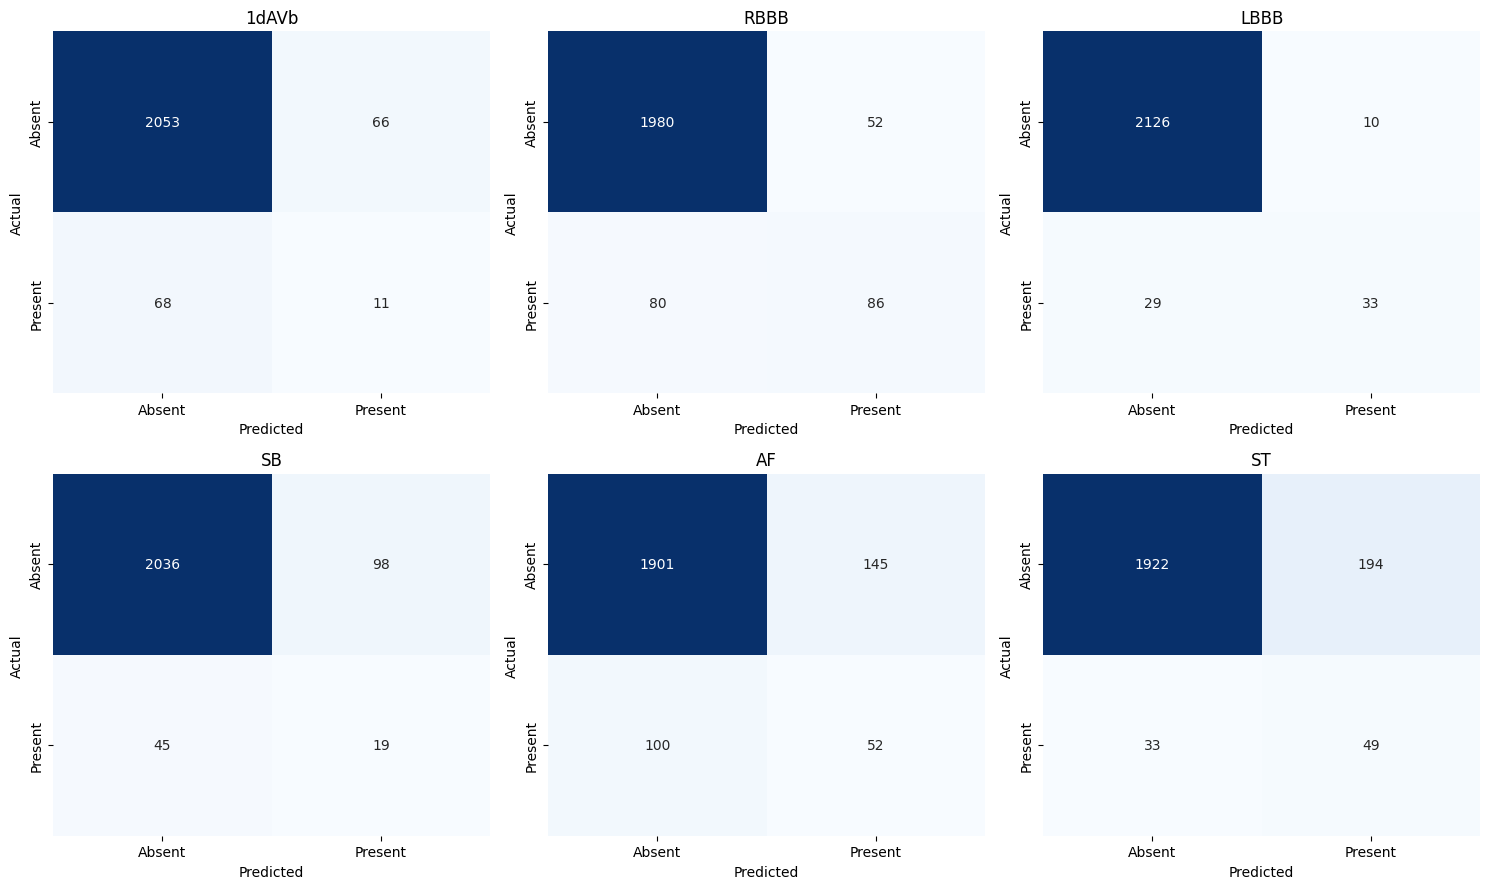

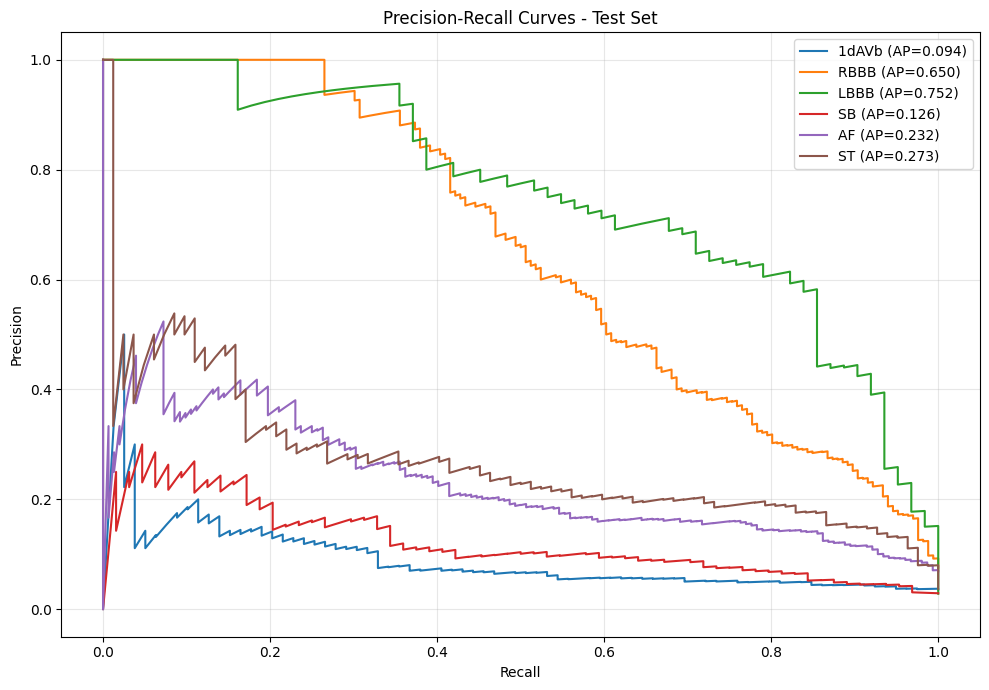

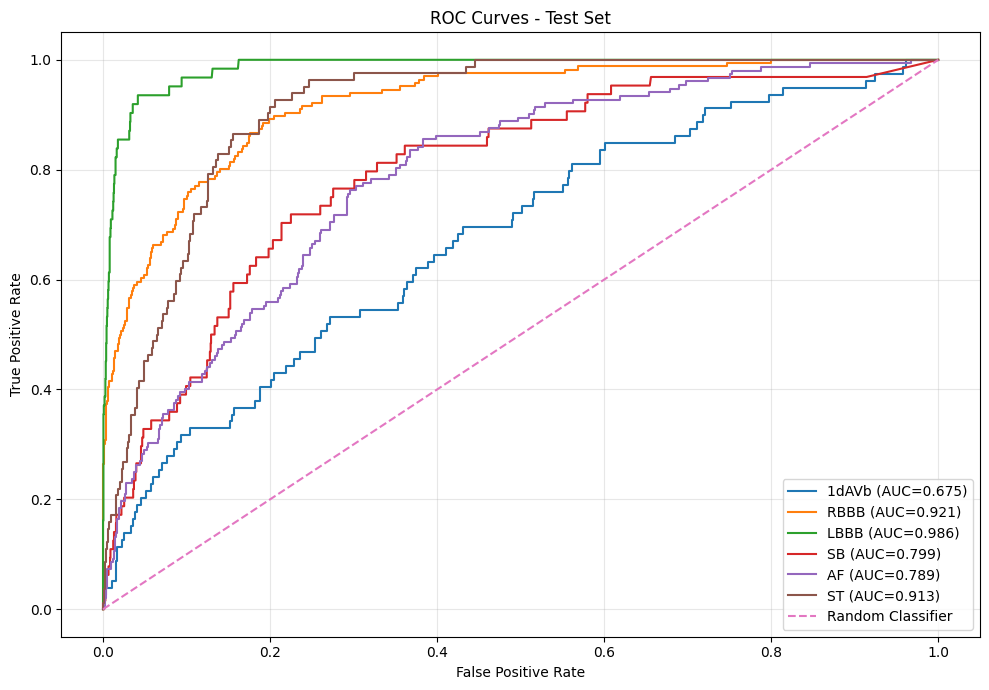

ROC curves saved successfully!
Running bootstrap analysis...

PER-CONDITION METRICS


,Condition,Precision,Recall,Specificity,F1_Score,Average_Precision,ROC_AUC,TN,FP,FN,TP
0,1dAVb,0.1429,0.1392,0.9689,0.1410,0.0936,0.6753,2053,66,68,11
1,RBBB,0.6232,0.5181,0.9744,0.5658,0.6497,0.9211,1980,52,80,86
2,LBBB,0.7674,0.5323,0.9953,0.6286,0.7518,0.9857,2126,10,29,33
3,SB,0.1624,0.2969,0.9541,0.2099,0.1264,0.7986,2036,98,45,19
4,AF,0.2640,0.3421,0.9291,0.2980,0.2321,0.7892,1901,145,100,52
5,ST,0.2016,0.5976,0.9083,0.3015,0.2727,0.9130,1922,194,33,49



OVERALL METRICS


,Metric,Value
0,Micro Precision,0.3067
1,Micro Recall,0.4132
2,Micro F1,0.3521
3,Macro F1,0.3575
4,Weighted F1,0.3760
5,Macro Average Precision,0.3544
6,Micro Average Precision,0.3767
7,Macro ROC-AUC,0.8471
8,Micro ROC-AUC,0.8737



BOOTSTRAP 95% CONFIDENCE INTERVALS


,Condition,Metric,95% CI Lower,95% CI Upper
0,1dAVb,F1,0.0719,0.2135
1,1dAVb,Precision,0.0706,0.2239
2,1dAVb,Recall,0.0714,0.2180
3,1dAVb,Specificity,0.9610,0.9760
4,RBBB,F1,0.4950,0.6320
5,RBBB,Precision,0.5439,0.7000
6,RBBB,Recall,0.4437,0.5943
7,RBBB,Specificity,0.9675,0.9803
8,LBBB,F1,0.5142,0.7259
9,LBBB,Precision,0.6275,0.8920



ALL EVALUATION OUTPUTS SAVED SUCCESSFULLY!
Google Drive location: /content/drive/MyDrive/ECG_Project/Results


In [ ]:

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    roc_auc_score,
    precision_recall_curve,
    classification_report
)

# ==========================================
# 1. SETUP
# ==========================================

BASE = "/content/drive/MyDrive/ECG_Project/Results"

METRICS = f"{BASE}/Metrics"
PLOTS = f"{BASE}/Plots"
REPORTS = f"{BASE}/Reports"

for folder in [METRICS, PLOTS, REPORTS]:
    os.makedirs(folder, exist_ok=True)

labels = LABELS
n_classes = len(labels)

# Use existing untouched test predictions
true = y_test
pred = y_test_pred
probs = y_test_probs

# ==========================================
# 2. PER-CONDITION METRICS
# ==========================================

results = []

for i, label in enumerate(labels):

    tn, fp, fn, tp = confusion_matrix(
        true[:, i], pred[:, i], labels=[0, 1]
    ).ravel()

    specificity = tn / (tn + fp) if (tn + fp) else 0

    results.append({
        "Condition": label,
        "Precision": precision_score(
            true[:, i], pred[:, i], zero_division=0
        ),
        "Recall": recall_score(
            true[:, i], pred[:, i], zero_division=0
        ),
        "Specificity": specificity,
        "F1_Score": f1_score(
            true[:, i], pred[:, i], zero_division=0
        ),
        "Average_Precision": average_precision_score(
            true[:, i], probs[:, i]
        ),
        "ROC_AUC": roc_auc_score(
            true[:, i], probs[:, i]
        ),
        "TN": tn,
        "FP": fp,
        "FN": fn,
        "TP": tp
    })

metrics_df = pd.DataFrame(results)

# ==========================================
# 3. OVERALL METRICS
# ==========================================

overall = pd.DataFrame([
    {
        "Metric": "Micro Precision",
        "Value": precision_score(true, pred, average="micro", zero_division=0)
    },
    {
        "Metric": "Micro Recall",
        "Value": recall_score(true, pred, average="micro", zero_division=0)
    },
    {
        "Metric": "Micro F1",
        "Value": f1_score(true, pred, average="micro", zero_division=0)
    },
    {
        "Metric": "Macro F1",
        "Value": f1_score(true, pred, average="macro", zero_division=0)
    },
    {
        "Metric": "Weighted F1",
        "Value": f1_score(true, pred, average="weighted", zero_division=0)
    },
    {
        "Metric": "Macro Average Precision",
        "Value": average_precision_score(true, probs, average="macro")
    },
    {
        "Metric": "Micro Average Precision",
        "Value": average_precision_score(true, probs, average="micro")
    },
    {
        "Metric": "Macro ROC-AUC",
        "Value": roc_auc_score(true, probs, average="macro")
    },
    {
        "Metric": "Micro ROC-AUC",
        "Value": roc_auc_score(true, probs, average="micro")
    }
])

# ==========================================
# 4. CONFUSION MATRICES
# ==========================================

fig, axes = plt.subplots(2, 3, figsize=(15, 9))

for i, ax in enumerate(axes.flat):

    cm = confusion_matrix(
        true[:, i], pred[:, i], labels=[0, 1]
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        cbar=False,
        xticklabels=["Absent", "Present"],
        yticklabels=["Absent", "Present"],
        ax=ax
    )

    ax.set_title(labels[i])
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

plt.tight_layout()
plt.savefig(
    f"{PLOTS}/test_confusion_matrices.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()
plt.close()

# ==========================================
# 5. PRECISION-RECALL CURVES
# ==========================================

plt.figure(figsize=(10, 7))

for i, label in enumerate(labels):

    precision, recall, _ = precision_recall_curve(
        true[:, i], probs[:, i]
    )

    ap = metrics_df.loc[i, "Average_Precision"]

    plt.plot(
        recall,
        precision,
        label=f"{label} (AP={ap:.3f})"
    )

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curves - Test Set")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    f"{PLOTS}/test_precision_recall_curves.png",
    dpi=300
)
plt.show()
plt.close()


# ==========================================
# 5B. ROC CURVES
# ==========================================

from sklearn.metrics import roc_curve

plt.figure(figsize=(10, 7))

for i, label in enumerate(labels):

    fpr, tpr, _ = roc_curve(
        true[:, i], probs[:, i]
    )

    auc_score = roc_auc_score(
        true[:, i], probs[:, i]
    )

    plt.plot(
        fpr,
        tpr,
        label=f"{label} (AUC={auc_score:.3f})"
    )

# Random classifier reference line
plt.plot(
    [0, 1], [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves - Test Set")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    f"{PLOTS}/test_roc_curves.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

print("ROC curves saved successfully!")


# ==========================================
# 6. BOOTSTRAP CONFIDENCE INTERVALS
# ==========================================

print("Running bootstrap analysis...")

rng = np.random.default_rng(42)
n_samples = len(true)
n_bootstrap = 1000

bootstrap_results = {
    label: {"F1": [], "Precision": [], "Recall": [], "Specificity": []}
    for label in labels
}

for b in range(n_bootstrap):

    indices = rng.integers(0, n_samples, size=n_samples)

    yt = true[indices]
    yp = pred[indices]

    for i, label in enumerate(labels):

        # Skip resamples with no positive or no negative examples
        if len(np.unique(yt[:, i])) < 2:
            continue

        tn, fp, fn, tp = confusion_matrix(
            yt[:, i], yp[:, i], labels=[0, 1]
        ).ravel()

        bootstrap_results[label]["F1"].append(
            f1_score(yt[:, i], yp[:, i], zero_division=0)
        )

        bootstrap_results[label]["Precision"].append(
            precision_score(yt[:, i], yp[:, i], zero_division=0)
        )

        bootstrap_results[label]["Recall"].append(
            recall_score(yt[:, i], yp[:, i], zero_division=0)
        )

        bootstrap_results[label]["Specificity"].append(
            tn / (tn + fp) if (tn + fp) else np.nan
        )

ci_rows = []

for label in labels:

    for metric, values in bootstrap_results[label].items():

        values = np.asarray(values)
        values = values[np.isfinite(values)]

        lower, upper = np.percentile(values, [2.5, 97.5])

        ci_rows.append({
            "Condition": label,
            "Metric": metric,
            "95% CI Lower": lower,
            "95% CI Upper": upper
        })

ci_df = pd.DataFrame(ci_rows)

# ==========================================
# 7. SAVE ALL TABLES
# ==========================================

metrics_df.to_csv(
    f"{METRICS}/per_condition_metrics.csv", index=False
)

overall.to_csv(
    f"{METRICS}/overall_metrics.csv", index=False
)

ci_df.to_csv(
    f"{METRICS}/bootstrap_confidence_intervals.csv",
    index=False
)

with pd.ExcelWriter(
    f"{REPORTS}/complete_test_evaluation.xlsx"
) as writer:

    metrics_df.to_excel(
        writer, sheet_name="Per Condition", index=False
    )

    overall.to_excel(
        writer, sheet_name="Overall Metrics", index=False
    )

    ci_df.to_excel(
        writer, sheet_name="Bootstrap 95 CI", index=False
    )

# Save text report
with open(
    f"{REPORTS}/complete_test_report.txt", "w"
) as f:

    f.write("FINAL RANDOM FOREST ECG EVALUATION\n\n")
    f.write("PER CONDITION METRICS\n")
    f.write(metrics_df.to_string(index=False))
    f.write("\n\nOVERALL METRICS\n")
    f.write(overall.to_string(index=False))
    f.write("\n\nBOOTSTRAP 95% CONFIDENCE INTERVALS\n")
    f.write(ci_df.to_string(index=False))

# ==========================================
# 8. DISPLAY RESULTS
# ==========================================

print("\nPER-CONDITION METRICS")
display(metrics_df.round(4))

print("\nOVERALL METRICS")
display(overall.round(4))

print("\nBOOTSTRAP 95% CONFIDENCE INTERVALS")
display(ci_df.round(4))

print("\nALL EVALUATION OUTPUTS SAVED SUCCESSFULLY!")
print("Google Drive location:", BASE)


In [17]:
import numpy as np
import pandas as pd
from sklearn.metrics import accuracy_score

# Overall exact-match accuracy (all six labels must be right for a record to count)
subset_accuracy = accuracy_score(y_test, y_test_pred)
print("OVERALL SUBSET ACCURACY:", round(subset_accuracy * 100, 2), "%")

# Per-disease accuracy
results = []
for i, label in enumerate(LABELS):
    acc = accuracy_score(y_test[:, i], y_test_pred[:, i])
    results.append({
        "Disease": label,
        "Accuracy (%)": round(acc * 100, 2)
    })

accuracy_df = pd.DataFrame(results)
print("\nPER-DISEASE ACCURACY")
display(accuracy_df)

OVERALL SUBSET ACCURACY: 66.56 %

PER-DISEASE ACCURACY


,Disease,Accuracy (%)
0,1dAVb,93.90
1,RBBB,93.99
2,LBBB,98.23
3,SB,93.49
4,AF,88.85
5,ST,89.67
